# Exploring TECH Clean CA Data on ASHP Upfront Costs

This notebook contains an exploratory data analysis of TECH Clean CA data on ASHP upfront costs.

Note that the TECH Clean team did a [thorough analysis](https://file.notion.so/f/f/948a2591-9f91-4fd1-8c4b-fcdded7e3438/8aba9dd6-0033-4e7c-8fc6-958e0e77b0d1/Heat_Pump_HVAC_Retrofit_Cost_Drivers_v4W3bW0_kiFU8k4.pdf?table=block&id=ecfed929-d62d-4aec-873f-6598f8251e6f&spaceId=948a2591-9f91-4fd1-8c4b-fcdded7e3438&expirationTimestamp=1764979200000&signature=C3v8GrhNLeCCGOEve2IWgobChQ-VOyUB8BYKJwydkms&downloadName=Heat_Pump_HVAC_Retrofit_Cost_Drivers_v4W3bW0_kiFU8k4.pdf) on drivers of project cost using the same dataset.


#### Setup

In [0]:
import matplotlib.pyplot as plt
import mlflow
import pandas as pd
import pyspark.sql.functions as F
import seaborn as sns
import statsmodels.api as sm

In [0]:
dbutils.widgets.dropdown(
    "mode", "feature", ["feature", "develop", "main", "hotfix"]
)  # mode to read/write delta tables in (see `util.modify_db_table_name()`)
MODE = dbutils.widgets.get("mode")

#### Load data

In [0]:
techclean_df = spark.table("processed.upfront_costs.techcleanca")
print(techclean_df.count())
techclean_df.limit(10).display()

24513


county_geoid,county_name,project_index,contractor_index,project_site_index,city,county,gas_iou_territory_number1,gas_iou_territory_number2,ca_climate_zone,disadvantaged_community,tech_equity_community,census_tract_median_household_income_dollars_thousands,claim_id,program_name,program_income_qualification,product_group,building_type,square_footage,year_built,living_size_sqft,number_of_bedrooms,panel_capacity_pre_install_amps,panel_capacity_post_install_amps,installed_equipment_description,material_category,product_type,brand_index,model_production_status,ahri_type,ahri_descriptor,hpwh_equipment_type,neea_tier,uniform_energy_factor,coefficient_of_performance_cop,rated_storage_volume_gal,first_hour_rating_gph,cta_2045,input_rate_kw,neea_cold_climate_efficiency,recovery_efficiency_per_uef_test_method_pct,connected_functionality,cee_minimum_tier,ja13_qualified,refrigerant,global_warming_potential_of_refrigerant,large_commercial_unit,usage_bin,hvac_equipment_type,ducted,ducting_type,compressor_type,cold_climate_designation,cooling_source,cooling_capacity_tons,heating_capacity_tons,eer,seer,hspf_region_iv,eer2,seer2,hspf2_region_iv,ex_ante_annual_electricity_savings_kwh,ex_ante_annual_gas_propane_savings_therms,ex_ante_annual_ghg_savings_metric_tons_co2e,count_units_installed,project_cost_raw,total_project_cost_per_unit_dollars,hpwh_norm_cost_dollars_gal,hvac_norm_cost_dollars_ton,total_electrical_upgrade_cost_qualifying_for_incentive_sgip_hpwh,incentive_1_dollars,incentive_1_funder,incentive_2_dollars,incentive_2_funders,total_incentive_received_by_contractor_dollars,start_date,installation_end_date,installation_duration_days,permit_request,had_panel_upgrade,type_of_panel_upgrade,emergency_replacement,emergency_backup_type,hpwh_operating_mode,location_hpwh_installed_in_bldg,condensate_pump_required,mixing_valve_installed,grid_connected,previous_wh_type,previous_wh_volume_gal,previous_wh_fuel_type,hpwh_temp_set_point,bedrooms_served,bathrooms_served,customer_enrolled_in_demand_response_program,tou_enrollment_rate,communication_module_add_on,had_duct_replacement,duct_sealing,smart_thermostat_included,manual_d_j_completed,performance_report_completed,previous_ac_type,previous_ac_model_number,previous_furnace_fuel_type,previous_furnace_model_number,furnace_status_after_install,contractor_project_count,contractor_duct_replacement_count,contractor_duct_sealing_count,contractor_smart_thermostat_count,contractor_manual_d_j_count,contractor_performance_report_count,state_geoid,program,is_cold_climate,heat_pump_type,year,month,city_state,cbsa_title,csa_title,id
06013,Contra Costa,1,668,14039,Other,Contra Costa County,Pacific Gas & Electric,null,12,false,false,176,1068379,TECH Clean California - Heat Pump Water Heating,Market Rate,HPWH,Single Family,null,1975,1781,3,null,null,Heat Pump Water Heater,neea_hpwh,Heat Pump Water Heater,25,Active,null,Heat Pump Water Heater,null,1,3.39,null,45,65,false,4.5,2.8,385.0,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,-1570.0,188.0,0.6651962,1,12000,12000,266.6666667,null,null,1100.0,TECH Clean California,2000,BayREN,3100.0,2022-05-27T00:00:00Z,2022-05-28 00:00:00,2,true,false,null,false,null,Heat Pump,"Garage, conditioned",FALSE,false,false,Storage,40,Natural Gas,null,null,null,FALSE,null,null,null,null,null,null,null,null,null,null,null,null,115,5,5,10,0,0,06,TECH Clean CA,false,Whole Home,2022,05,"Other, CA","San Francisco-Oakland-Berkeley, CA","San Jose-San Francisco-Oakland, CA",bd90ee15b0675421e32c6ab097f1c4d1841c3ed7ce19dec1fb266daef1005d8c
06001,Alameda,2,415,6022,LIVERMORE,Alameda County,Pacific Gas & Electric,null,12,false,false,153,1071514,TECH Clean California - Heat Pump Water Heating,Market Rate,HPWH,Single Family,null,1998,3870,3,null,null,Heat Pump Water Heater,neea_hpwh,Heat Pump Water Heater,25,Active,null,Heat Pump Water Heater,null,1,3.48,null,75,87,false,4.5,3.1,292.0,null,null,null,null,null,null,null,null,null,null,null,null

#### Explore

In [0]:
# We have mostly HVAC heat pump records with some HPWH records
techclean_df.groupBy("product_group", "product_type").count().display()
# Let's filter this exploration to just HVAC heat pumps
techclean_df = techclean_df.filter(F.col("product_group") == "HVAC")

product_group,product_type,count
HVAC,Heat Pump HVAC,20721
HPWH,Heat Pump Water Heater,3792


In [0]:
# Convert to pandas
techclean_pdf = techclean_df.toPandas()
# Correct dtypes
techclean_pdf["project_cost_raw"] = pd.to_numeric(techclean_pdf["project_cost_raw"])
techclean_pdf["installation_end_date"] = pd.to_datetime(techclean_pdf["installation_end_date"])
techclean_pdf["square_footage"] = pd.to_numeric(techclean_pdf["square_footage"])

In [0]:
techclean_pdf.columns.tolist()

['county_geoid',
 'county_name',
 'project_index',
 'contractor_index',
 'project_site_index',
 'city',
 'county',
 'gas_iou_territory_number1',
 'gas_iou_territory_number2',
 'ca_climate_zone',
 'disadvantaged_community',
 'tech_equity_community',
 'census_tract_median_household_income_dollars_thousands',
 'claim_id',
 'program_name',
 'program_income_qualification',
 'product_group',
 'building_type',
 'square_footage',
 'year_built',
 'living_size_sqft',
 'number_of_bedrooms',
 'panel_capacity_pre_install_amps',
 'panel_capacity_post_install_amps',
 'installed_equipment_description',
 'material_category',
 'product_type',
 'brand_index',
 'model_production_status',
 'ahri_type',
 'ahri_descriptor',
 'hpwh_equipment_type',
 'neea_tier',
 'uniform_energy_factor',
 'coefficient_of_performance_cop',
 'rated_storage_volume_gal',
 'first_hour_rating_gph',
 'cta_2045',
 'input_rate_kw',
 'neea_cold_climate_efficiency',
 'recovery_efficiency_per_uef_test_method_pct',
 'connected_functionali

Installations are fairly widely distributed across CA.

In [0]:
techclean_pdf["county"].value_counts()

Riverside County          2732
Los Angeles County        2499
San Diego County          2336
Sacramento County         2250
Orange County             1445
Alameda County            1139
Santa Clara County         863
Fresno County              852
Contra Costa County        843
Solano County              578
San Bernardino County      561
San Mateo County           522
Sonoma County              490
Marin County               414
Placer County              394
Stanislaus County          383
Kern County                317
Ventura County             285
Yolo County                250
Santa Cruz County          182
Butte County               164
San Joaquin County         154
Monterey County            113
Napa County                112
Shasta County              109
San Francisco County        94
El Dorado County            80
Merced County               64
Madera County               64
Nevada County               61
Mendocino County            59
San Luis Obispo County      56
Santa Ba

But occurred in two main pushes in 2022 and 2023.

<Axes: xlabel='installation_end_date', ylabel='Density'>

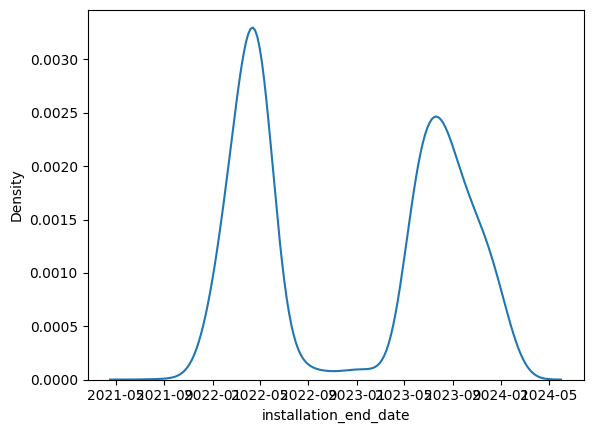

In [0]:
sns.kdeplot(techclean_pdf["installation_end_date"])

Almost all in single-family homes. How old are these homes?

In [0]:
techclean_pdf["building_type"].value_counts()

Single Family    20463
Multifamily        258
Name: building_type, dtype: int64

In [0]:
techclean_pdf["year_built"].isna().value_counts()

False    18864
True      1857
Name: year_built, dtype: int64

<Axes: xlabel='year_built', ylabel='Density'>

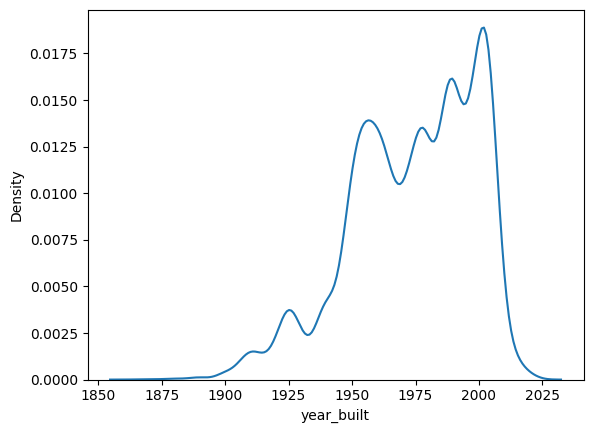

In [0]:
sns.kdeplot(techclean_pdf["year_built"])

Project costs averaged around $20k.

count    20438.000000
mean     20246.930162
std       8692.533539
min       2000.000000
25%      14348.500000
50%      18758.000000
75%      24830.647500
max      70000.000000
Name: project_cost_raw, dtype: float64


<Axes: xlabel='project_cost_raw', ylabel='Density'>

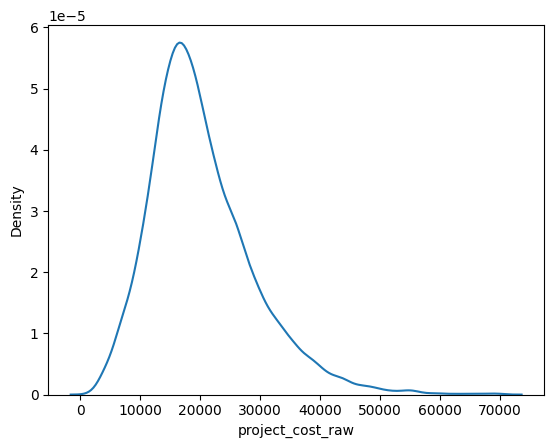

In [0]:
print(techclean_pdf["project_cost_raw"].describe())
sns.kdeplot(techclean_pdf["project_cost_raw"])

There are a small number of potentially important features we currently expect to be able to get in other
datasets and future prediction contexts. Let's look into these:

In [0]:
techclean_pdf[["project_cost_raw", "square_footage", "heating_capacity_tons", "seer", "hspf_region_iv"]].describe()

,project_cost_raw,square_footage,heating_capacity_tons,seer,hspf_region_iv
count,20438.000000,20594.000000,20711.000000,18220.000000,18220.000000
mean,20246.930162,2143.241187,3.262651,17.480269,9.766682
std,8692.533539,1562.310067,0.955058,2.117295,1.133248
min,2000.000000,190.000000,0.580000,12.000000,7.200000
25%,14348.500000,1443.000000,2.670000,16.000000,9.000000
50%,18758.000000,1900.000000,3.080000,17.500000,9.600000
75%,24830.647500,2528.000000,4.000000,19.000000,10.500000
max,70000.000000,94526.000000,5.670000,33.100000,14.200000


In [0]:
techclean_pdf[["project_cost_raw", "square_footage", "heating_capacity_tons", "seer", "hspf_region_iv"]].corr(
    numeric_only=True
)

,project_cost_raw,square_footage,heating_capacity_tons,seer,hspf_region_iv
project_cost_raw,1.000000,0.194419,0.291083,0.150687,0.143390
square_footage,0.194419,1.000000,0.189511,-0.019007,-0.037006
heating_capacity_tons,0.291083,0.189511,1.000000,-0.137747,-0.130065
seer,0.150687,-0.019007,-0.137747,1.000000,0.617175
hspf_region_iv,0.143390,-0.037006,-0.130065,0.617175,1.000000


Let's visualize:

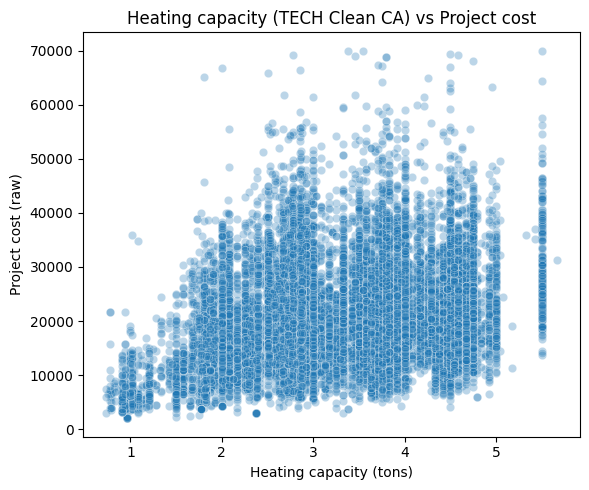

In [0]:
plt.figure(figsize=(6, 5))
sns.scatterplot(data=techclean_pdf, x="heating_capacity_tons", y="project_cost_raw", alpha=0.3)
plt.title("Heating capacity (TECH Clean CA) vs Project cost")
plt.xlabel("Heating capacity (tons)")
plt.ylabel("Project cost (raw)")
plt.tight_layout()
plt.show()

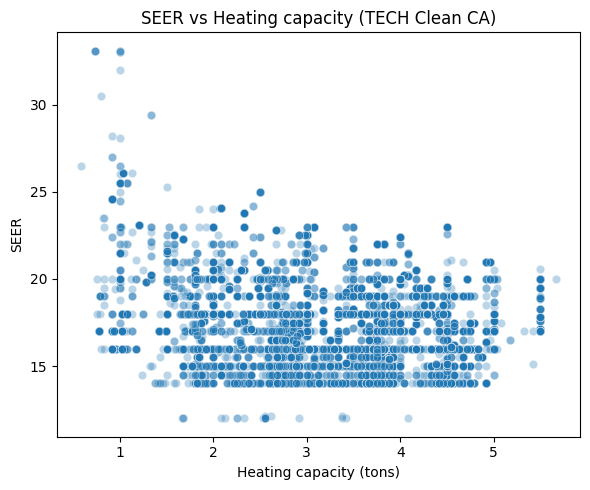

In [0]:
plt.figure(figsize=(6, 5))
sns.scatterplot(data=techclean_pdf, x="heating_capacity_tons", y="seer", alpha=0.3)
plt.title("SEER vs Heating capacity (TECH Clean CA)")
plt.xlabel("Heating capacity (tons)")
plt.ylabel("SEER")
plt.tight_layout()
plt.show()

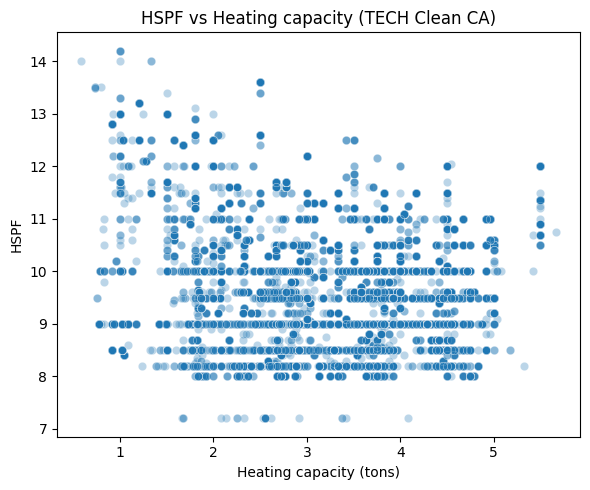

In [0]:
plt.figure(figsize=(6, 5))
sns.scatterplot(data=techclean_pdf, x="heating_capacity_tons", y="hspf_region_iv", alpha=0.3)
plt.title("HSPF vs Heating capacity (TECH Clean CA)")
plt.xlabel("Heating capacity (tons)")
plt.ylabel("HSPF")
plt.tight_layout()
plt.show()

What does a simple multiple linear regression model with these variables tell us?

In [0]:
mlflow.autolog(disable=True)

techclean_pdf_no_nas = techclean_pdf.dropna(
    subset=["project_cost_raw", "square_footage", "heating_capacity_tons", "seer", "hspf_region_iv"]
)
print(techclean_pdf_no_nas.shape[0])
X = sm.add_constant(techclean_pdf_no_nas[["square_footage", "heating_capacity_tons", "seer", "hspf_region_iv"]])
y = techclean_pdf_no_nas["project_cost_raw"]

model = sm.OLS(y, X).fit()
print(model.summary())

17836
                            OLS Regression Results                            
Dep. Variable:       project_cost_raw   R-squared:                       0.147
Model:                            OLS   Adj. R-squared:                  0.147
Method:                 Least Squares   F-statistic:                     766.5
Date:                Fri, 06 Nov 2026   Prob (F-statistic):               0.00
Time:                        18:56:01   Log-Likelihood:            -1.8576e+05
No. Observations:               17836   AIC:                         3.715e+05
Df Residuals:                   17831   BIC:                         3.716e+05
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                 -7

The R-squared of this model is quite low - but not very different from the R-squared reported
by the TECH Clean CA team's analysis, 0.245.